In [1]:
from matplotlib import pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
import pandas as pd
import os
import ast
from configparser import ConfigParser

In [2]:
DATAPATH = '../../data/output'
CONFIGPATH = '../configurations/app-remote.ini'

parser = ConfigParser()
parser.read(CONFIGPATH)

# Configuration
episodes = int(parser.get("BUS", "EPISODES"))
timelimit = parser.getfloat("BUS", "TIMELIMIT") # multiplier, not the real timelimit
actions = parser.get("BUS", "ACTION_SPACE").split(',')
action_dim = len(actions)
action_resolution = parser.getint("BUS", "ACTION_SPACE_RESOLUTION")
eps = parser.getfloat("BUS", "EPS")
eps_decay_strategy = parser.get("BUS", "EPS_DECAY_STRATEGY")
eps_decay = parser.getfloat("BUS", "EPS_DECAY")
eps_min = parser.getfloat("BUS", "EPS_MIN")
buffersize = int(parser.get("BUS", "BUFFERSIZE"))
min_experience = int(parser.get("BUS", "MIN_EXPERIENCE"))
target_update_threshold = int(parser.get("BUS", "TARGET_UPDATE_THRESHOLD"))
tau = parser.getfloat("BUS", "TAU")
gamma = parser.getfloat("BUS", "GAMMA")
penalty = int(parser.get("BUS", "PENALTY"))
reward = parser.getint("BUS", "REWARD")
q_net_layers = ast.literal_eval(parser.get("BUS", "DQN_LAYERS"))
batchsize = int(parser.get("BUS", "BATCHSIZE"))
lr_decay = parser.getboolean("BUS", "LR_DECAY")
lr_decay_steps = parser.getint("BUS", "LR_DECAY_STEPS")
velocity = float(parser.get("BUS", "VELOCITY"))

config = {'episodes': episodes, 
          'actions': actions,
          'eps decay': eps_decay,
          'eps min': eps_min,
          'penalty': penalty,
          'learning rate decay': lr_decay,
          'batchsize': batchsize
         }

# Experiment with different agent configurations

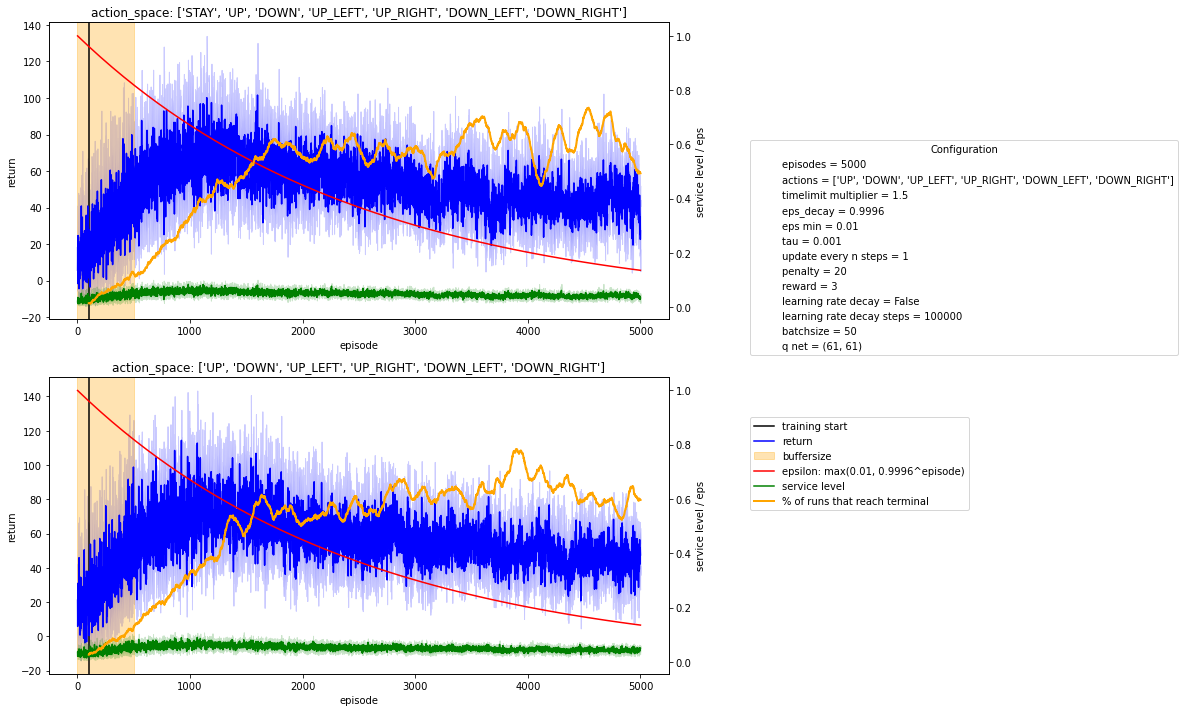

In [4]:
RESULTS = 'search_action_space_experiments_20211220-112049.csv'
COLS = ['episode', 'return', 'service_level', 'lr', 'reached_destination', 'distance', 'duration']

config = {'episodes': episodes, 
          'actions': actions,
          'timelimit multiplier': timelimit,
          'eps_decay': eps_decay,
          'eps min': eps_min,
          'tau': tau,
          'update every n steps': target_update_threshold,
          'penalty': penalty,
          'reward': reward,
          'learning rate decay': lr_decay,
          'learning rate decay steps': lr_decay_steps,
          'batchsize': batchsize,
          'q net': q_net_layers
         }

results = pd.read_csv(os.path.join(DATAPATH, 'returns', RESULTS))
experiments = list(set(results) - set(COLS))

for e in experiments:
    config.pop(e, None) # remove this from configuration legend

n_experiments = len(experiments)
if n_experiments > 2:
    raise NotImplementedError('more than two simultaneous experiments are currently not supported')
elif n_experiments == 2:
    e1 = results[experiments[0]]
    e2 = results[experiments[1]]
    n_e1 = e1.nunique()
    n_e2 = e2.nunique()
    fig, ax = plt.subplots(n_e1, n_e2, figsize=(8*n_e1,5*n_e2))
    ii = 0
    
    for i, (name, group) in enumerate(results.groupby(experiments)):
        group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()
        
        if i >= n_e1:
            ii = i // n_e1
            i -= n_e1

        # annotations
        if 'buffersize' in experiments:
            buffersize_i = experiments.index('buffersize')
            ax[ii][i].axvspan(0, name[buffersize_i], color='orange', alpha=.3, label='buffersize')
        else:
            ax[ii][i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[ii][i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[ii][i].twinx()
        ax2 = ax[ii][i].twinx()
        if 'eps_decay_strategy' in experiments:
            epsdecaystrategy_i = experiments.index('eps_decay_strategy')
            eps_decay_strategy = name[epsdecaystrategy_i]
        if eps_decay_strategy == 'exp':
            if 'eps_decay' in experiments:
                epsdecay_i = experiments.index('eps_decay')
                sns.lineplot(x=x_, y=np.maximum(name[epsdecay_i]**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {name}^episode)', legend=False)
            else:
                sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {eps_decay}^episode)', legend=False)
        if eps_decay_strategy == 'linear':
            sns.lineplot(x=x_, y=np.maximum(1-(1/episodes)x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, 1-(1/episodes)*episode)', legend=False)
        if eps_decay_strategy == 'none':
            config.pop('eps_decay', None)
            config.pop('eps_min', None)
            config['eps'] = eps
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', color='blue', label='return', ax=ax[ii][i], legend=False)
    #         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
    #         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
        sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='orange', label='% of runs that reach terminal', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[ii][i].set_title(f'{experiments}: {name}')

    handles, labels = [(a + b) for a, b in zip(ax[ii][i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]

elif n_experiments == 1:
    n = results[experiments[0]].nunique()
    fig, ax = plt.subplots(n, figsize=(10,5*n))
    
    for i, (name, group) in enumerate(results.groupby(experiments)):
        group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        if 'buffersize' in experiments:
            ax[i].axvspan(0, name, color='orange', alpha=.3, label='buffersize')
        else:
            ax[i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        if 'eps_decay_strategy' in experiments:
            eps_decay_strategy = name
        if eps_decay_strategy == 'exp':
            if 'eps_decay' in experiments:
                sns.lineplot(x=x_, y=np.maximum(name**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {name}^episode)', legend=False)
            else:
                sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {eps_decay}^episode)', legend=False)
        if eps_decay_strategy == 'linear':
            sns.lineplot(x=x_, y=np.maximum(1-(1/episodes)x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, 1-(1/episodes)*episode)', legend=False)
        if eps_decay_strategy == 'none':
            config.pop('eps_decay', None)
            config.pop('eps_min', None)
            config['eps'] = eps
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', color='blue', label='return', ax=ax[i], legend=False)
    #         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
    #         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
        sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='orange', linewidth=2, label='% of runs that reach terminal', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'{experiments[0]}: {name}')

    handles, labels = [(a + b) for a, b in zip(ax[i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.35), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.65), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,lgd2), bbox_inches='tight')
plt.show()

# Single (averaged) agent evaluation

In [4]:
RESULTS = '5000_episodes_returns_20211213-110949.csv'
results = pd.read_csv(os.path.join(DATAPATH, RESULTS))

# %%
# results = results[results['penalty'] == 15]
results['return_MA'] = results['return'].rolling(20).mean()
results['service_level_MA'] = results['service_level'].rolling(20).mean()
results['reached_destination_MA'] = results['reached_destination'].rolling(100).mean()

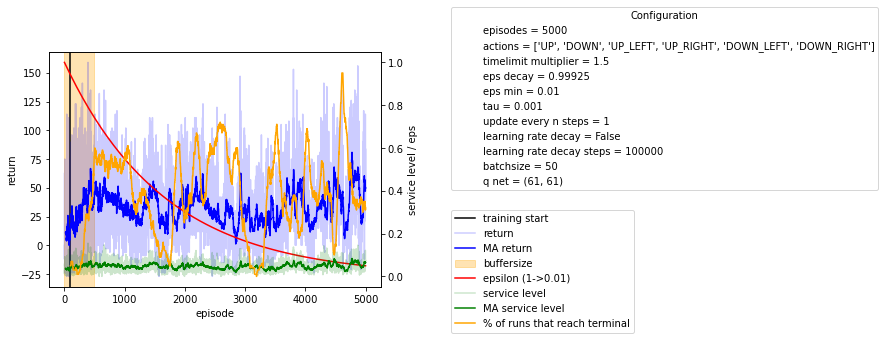

In [7]:
fig, ax = plt.subplots()
# annotations
plt.axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
plt.axvline(min_experience, color='black', label='training start')
x_ = np.linspace(1,episodes)
ax_ = plt.twinx(ax)
ax2 = ax.twinx()
sns.lineplot(x=x_, y=np.maximum(0.9994**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
ax_.set_axis_off() # hide this axis

sns.lineplot(data=results, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
sns.lineplot(data=results, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
sns.lineplot(data=results, x='episode', y='reached_destination_MA', color='orange', label='% of runs that reach terminal', ax=ax2, legend=False)

# plt.title('Experiment with tanh activation function in hidden layers')
ax2.set_ylabel('service level / eps')

handles, labels = [(a + b) for a, b in zip(ax.get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.2), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.8), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,lgd2), bbox_inches='tight')
plt.show()

## find best of runs

In [5]:
runs = [
    "5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-080435.csv",
"5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-094508.csv",
"5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-095225.csv",
"5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-095902.csv",
"5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-101402.csv",
"5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-102753.csv",
"5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-102923.csv",
"5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-104350.csv",
"5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-104834.csv",
"5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-112042.csv",
"5000_episodes_action_space=['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-082514.csv",
"5000_episodes_action_space=['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-093235.csv",
"5000_episodes_action_space=['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-093336.csv",
"5000_episodes_action_space=['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-094630.csv",
"5000_episodes_action_space=['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-095455.csv",
"5000_episodes_action_space=['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-095641.csv",
"5000_episodes_action_space=['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-103209.csv",
"5000_episodes_action_space=['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-105857.csv",
"5000_episodes_action_space=['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-110148.csv",
"5000_episodes_action_space=['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-110254.csv",
]

In [7]:
LAST_N = 100

evaluate_results = []

for r in runs:
    run_results = pd.read_csv(os.path.join(DATAPATH, 'returns', r))
    e_cols = list(set(run_results) - set(['service_level', 'episode', 'reached_destination', 'lr', 'return']))
    evaluate_results.append(
        {'run': r,
         'mean_service': run_results["service_level"].mean(), 
         'last_mean_service': run_results["service_level"][-LAST_N:].mean(), 
         'reached_destination': run_results["reached_destination"].mean(), 
         'last_reached_destination': run_results["reached_destination"][-LAST_N:].mean(),
         'experiments': str(run_results.loc[0,e_cols].to_dict())}
    )
    # print(f'Run {r}: \n\tLast runs service level: {run_results["service_level"][-10:].mean()} \n\tLast runs of reaching destination: {run_results["reached_destination"][-10:].mean()}\n\tMean service level: {run_results["service_level"].mean()} \n\tMean of reaching destination: {run_results["reached_destination"].mean()}\n')

In [8]:
evaluate_results = pd.DataFrame.from_records(evaluate_results)
evaluate_results.groupby('experiments').mean()

,mean_service,last_mean_service,reached_destination,last_reached_destination
experiments,,,,
"{'action_space': ""['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']""}",0.047258,0.040262,0.49058,0.493
"{'action_space': ""['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']""}",0.050478,0.042159,0.50130,0.597


In [26]:
# filter out agents that do not reach the destination reliably
evaluate_results_filtered = evaluate_results[evaluate_results['last_reached_destination'] >= 0.8]
# filter out agents that are not stable
# evaluate_results_filtered = evaluate_results_filtered[evaluate_results_filtered['last_mean_service']>=evaluate_results_filtered['mean_service']]
evaluate_results_filtered

,run,mean_service,last_mean_service,reached_destination,last_reached_destination,experiments
7,"5000_episodes_action_space=['STAY', 'UP', 'DOW...",0.049407,0.037061,0.4622,0.88,"{'action_space': ""['STAY', 'UP', 'DOWN', 'UP_L..."
10,"5000_episodes_action_space=['UP', 'DOWN', 'UP_...",0.050782,0.036199,0.6846,0.80,"{'action_space': ""['UP', 'DOWN', 'UP_LEFT', 'U..."
11,"5000_episodes_action_space=['UP', 'DOWN', 'UP_...",0.049140,0.043132,0.5518,0.80,"{'action_space': ""['UP', 'DOWN', 'UP_LEFT', 'U..."
12,"5000_episodes_action_space=['UP', 'DOWN', 'UP_...",0.049626,0.043315,0.5306,0.83,"{'action_space': ""['UP', 'DOWN', 'UP_LEFT', 'U..."
15,"5000_episodes_action_space=['UP', 'DOWN', 'UP_...",0.050730,0.039719,0.5148,0.83,"{'action_space': ""['UP', 'DOWN', 'UP_LEFT', 'U..."


In [27]:
evaluate_results_filtered.loc[12, 'run']

"5000_episodes_action_space=['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-093336.csv"

# Benchmark best run

In [43]:
BENCHMARK_PATH = 'benchmarks'
# BENCHMARK = '100_episodes_benchmark_20211220-200031.csv' # with stay
BENCHMARK = '100_episodes_benchmark_20211220-203730.csv' # without stay
ROLLING = 1

<AxesSubplot:xlabel='episode', ylabel='service_level_MA'>

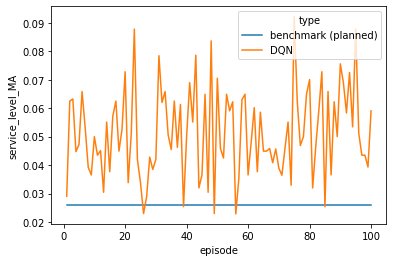

In [44]:
benchmark_results = pd.read_csv(os.path.join(DATAPATH, BENCHMARK_PATH, BENCHMARK))
# noinspection JupyterPackage
benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level'].rolling(ROLLING).mean()
benchmark_results.loc[benchmark_results['type']=='benchmark (planned)', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='benchmark (planned)', 'service_level'].rolling(ROLLING).mean()

sns.lineplot(data=benchmark_results, x='episode', y='service_level_MA', hue='type')

In [45]:
print('Service level:')
display(benchmark_results.groupby('type').describe()['service_level'])

print('Distance:')
display(benchmark_results.groupby('type').describe()['distance'])

print('Duration:')
display(benchmark_results.groupby('type').describe()['duration'])

Service level:


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
DQN,100.0,0.051310,1.556129e-02,0.022831,0.039280,0.050000,0.062500,0.092308
benchmark (planned),100.0,0.026087,1.046078e-17,0.026087,0.026087,0.026087,0.026087,0.026087


Distance:


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
DQN,95.0,18248.990370,1.936580e+03,13961.935183,16577.860575,18353.131407,19648.317898,20969.493890
benchmark (planned),100.0,12358.056064,7.312613e-12,12358.056064,12358.056064,12358.056064,12358.056064,12358.056064


Duration:


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
DQN,95.0,36.497981,3.873161,27.92387,33.155721,36.706263,39.296636,41.938988
benchmark (planned),100.0,48.000000,0.000000,48.00000,48.000000,48.000000,48.000000,48.000000


In [31]:
# TODO: add to benchmark stats
benchmark_results.loc[benchmark_results['type']=='DQN', 'reached_destination'].mean()

0.95

In [32]:
benchmark_stats = benchmark_results.groupby('type').describe().loc[:,(['service_level', 'distance', 'duration'], ['min', 'mean', 'max'])]
benchmark_stats.loc[:,('distance',['min', 'mean', 'max'])] = benchmark_stats.loc[:,('distance',['min', 'mean', 'max'])] / 1000
benchmark_stats.loc['DQN','destination'] = '{:.0%}'.format(benchmark_results.loc[benchmark_results['type']=='DQN', 'reached_destination'].mean())
benchmark_stats.loc['benchmark (planned)','destination'] = '100%'

In [33]:
benchmark_stats

service_level                       distance             \
                              min      mean       max        min       mean   
type                                                                          
DQN                      0.020833  0.049195  0.083123  13.961935  18.331207   
benchmark (planned)      0.026087  0.026087  0.026087  12.358056  12.358056   

                                duration                       destination  
                           max       min       mean        max              
type                                                                        
DQN                  21.088599  27.92387  36.662414  42.177198         95%  
benchmark (planned)  12.358056  48.00000  48.000000  48.000000        100%

In [36]:
COLUMN_FORMAT = 'lrrrrrrrrr'

latex = benchmark_stats.to_latex(column_format=COLUMN_FORMAT, float_format="{:,.2f}".format, caption='Benchmark configurations', label='tab:benchmarks', position='t')

# multicolumn headers centered
latex = latex.replace('\multicolumn{3}{l}', '\multicolumn{3}{c}')

# rename benchmark to BVG
latex = latex.replace('benchmark (planned)', 'BVG')

print(latex)

\begin{table}[t]
\centering
\caption{Benchmark configurations}
\label{tab:benchmarks}
\begin{tabular}{lrrrrrrrrr}
\toprule
{} & \multicolumn{3}{c}{service\_level} & \multicolumn{3}{c}{distance} & \multicolumn{3}{c}{duration} & destination \\
{} &           min & mean &  max &      min &  mean &   max &      min &  mean & \multicolumn{2}{l}{max} \\
type                &               &      &      &          &       &       &          &       &       &             \\
\midrule
DQN                 &          0.02 & 0.05 & 0.08 &    13.96 & 18.33 & 21.09 &    27.92 & 36.66 & 42.18 &         95\% \\
BVG &          0.03 & 0.03 & 0.03 &    12.36 & 12.36 & 12.36 &    48.00 & 48.00 & 48.00 &        100\% \\
\bottomrule
\end{tabular}
\end{table}



# Code scrapyard

In [12]:
RESULTS = [
    '5000_episodes_returns_20211216-021413.csv',
    '5000_episodes_returns_20211216-030028.csv',
    '5000_episodes_returns_20211216-030903.csv',
    '5000_episodes_returns_20211216-031023.csv',
    '5000_episodes_returns_20211216-034113.csv',
    '5000_episodes_returns_20211216-041024.csv',
    '5000_episodes_returns_20211216-041230.csv',
    '5000_episodes_returns_20211216-041816.csv',
    '5000_episodes_returns_20211216-042849.csv',
    '5000_episodes_returns_20211216-043242.csv',
    '5000_episodes_returns_20211216-044310.csv',
    '5000_episodes_returns_20211216-044529.csv',
    '5000_episodes_returns_20211216-050700.csv',
    '5000_episodes_returns_20211216-050900.csv',
    '5000_episodes_returns_20211216-050953.csv',
    '5000_episodes_returns_20211216-051702.csv',
    '5000_episodes_returns_20211216-052029.csv',
    '5000_episodes_returns_20211216-052151.csv',
    '5000_episodes_returns_20211216-052437.csv',
    '5000_episodes_returns_20211216-054150.csv'
]

re = []

for r in RESULTS:
    re.append(pd.read_csv(os.path.join(DATAPATH, r)))
    
results = pd.concat(re, axis=0, ignore_index=True)
results.to_csv(os.path.join(DATAPATH,'search_reward_experiments_20211216-000000.csv'), index=False)

<AxesSubplot:label='2cc29999-6d10-4bc8-a731-3086deb3bf5c', xlabel='episode', ylabel='reached_destination'>

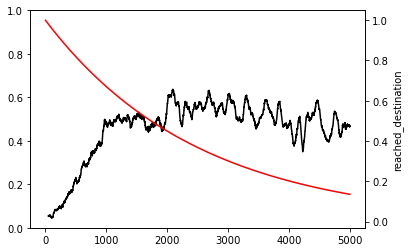

In [57]:
fig, ax = plt.subplots()
# sns.lineplot(ax=ax, data=results, x='episode', y='return', hue='reached_destination')
reached = results.groupby('episode')['reached_destination'].mean().rolling(50).mean().reset_index()
ax2 = ax.twinx()
sns.lineplot(ax=ax2, data=reached, x='episode', y='reached_destination', color='black', alpha=1)
sns.lineplot(x=x_, y=np.maximum(0.9996**x_, eps_min), color='red', ax=ax2)